<a href="https://colab.research.google.com/github/BenFreilichUVA/walmart-hurricane-project/blob/main/notebooks/2026_10_23_%E2%80%94_Midterm_Checkpoint_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [1]:
team_setup = {
    'team_name': 'Thomas Snyder and Ben Freilich',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Ben Freilich', 'github': 'BenFreilichUVA'},
        {'name': 'Thomas Snyder', 'github': 'TommySnyd'},
    ],
    'repo_url': 'https://github.com/BenFreilichUVA/walmart-hurricane-project',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/BenFreilichUVA/walmart-hurricane-project/blob/main/CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Ben',           # nice to have
    'meeting_time': 'Wednesday 3:30 PM',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': ['store_id has 60 different spellings of 12 total stores, with formatting errors including spacing and uppercasing.',
                            'category has 37 different spellings of 10 total categories, with various wording and capitalization errors.',
                            'Timestamps use different formats and have blank rows.',
                            'unit_price is stored as text, as there are dollar signs for some of the values, which has to be corrected.',
                            '30 duplicate rows and 130 negative quantities, which have to be addressed by either removing or undoing it.'],              # nice to have, five specific problems
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  done - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [2]:
import subprocess

!rm -rf /content/walmart-hurricane-project
!git clone -q https://github.com/BenFreilichUVA/walmart-hurricane-project.git /content/walmart-hurricane-project
REPO_PATH = '/content/walmart-hurricane-project'      # your local clone of the team repo

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

7c79e08 Added via upload


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [3]:
from pathlib import Path
import pandas as pd
import sqlite3

DATA = Path(REPO_PATH) / 'data'

transactions = pd.read_csv(DATA / 'walmart_transactions.csv')
stores       = pd.read_csv(DATA / 'store_locations.csv')
products     = pd.read_csv(DATA / 'product_catalog.csv')
centers      = pd.read_csv(DATA / 'distribution_centers.csv')

conn = sqlite3.connect(DATA / 'inventory_and_sales.db')
daily_sales = pd.read_sql('SELECT * FROM daily_sales_summary', conn)
inventory   = pd.read_sql('SELECT * FROM inventory_levels', conn)
conn.close()

decision_log = {}


#####################################################
# TRANSACTIONS
#####################################################
# Fixing the Store IDS for the transaction DataFrame
def fix_store_ids(df):
    clean = df.copy()
    before = clean['store_id'].nunique()
    clean['store_id'] = (clean['store_id']
                         .str.strip()
                         .str.upper()
                         .str.replace(r'^FL[-_]?', 'FL-', regex=True))
    after = clean['store_id'].nunique()
    # Assertions to ensure this step properly worked
    assert clean['store_id'].nunique() == 12, 'expected 12 stores'
    assert clean['store_id'].str.fullmatch(r'FL-\d{3}').all(), 'some IDs are not in FL-### format'
    assert len(clean) == len(df), 'cleaning should not drop rows'
    decision_log['transactions: store_id'] = f'Standardized store IDs to FL-###, removing unnecessary spacing and uppercasing ({before} spellings condensed to {after} spellings).'
    return clean

# Fixing the Categories for the transaction DataFrame
category_map = {
    'emergency': 'Emergency', 'emergency supplies': 'Emergency', 'grocery': 'Grocery', 'groceries': 'Grocery',
    'electronics': 'Electronics', 'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'household': 'Household', 'household essentials': 'Household', 'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast', 'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'snacks': 'Snacks', 'health': 'Health', 'health & wellness': 'Health',
}

def fix_categories(df, db_categories):
    clean = df.copy()
    before = clean['category'].nunique()
    clean['category'] = clean['category'].str.strip().str.lower().map(category_map)
    after = clean['category'].nunique()
    #Assertions to ensure this step properly worked
    assert clean['category'].isna().sum() == 0, 'some categories did not map'
    assert set(clean['category']) == set(db_categories), 'categories do not match the database'
    decision_log['transactions: category'] = f'Mapped category names down to the 10 used in the database ({before} spellings condensed to {after} spellings).'
    return clean

# Fixing the unit_price column to not be stored as text, and to instead be stored as a number
def fix_unit_price(df):
    clean = df.copy()
    dollar_rows = clean['unit_price'].astype(str).str.contains('$', regex=False).sum()

    clean['unit_price'] = pd.to_numeric(
        clean['unit_price'].astype(str).str.replace('$', '', regex=False).str.strip(),
        errors='coerce')

    #Assertions to ensure this step properly worked
    assert clean['unit_price'].isna().sum() == 0, 'some prices did not convert'
    assert (clean['unit_price'] > 0).all(), 'found a zero or negative price'
    decision_log['transactions: unit_price'] = f'Removed $ from {dollar_rows:,} prices and converted the column from text to numbers'
    return clean

# Converting all of the timestamps into the same format
formats = ['%Y-%m-%d %H:%M:%S',   # 2024-09-15 18:36:16
           '%Y-%m-%dT%H:%M:%S',   # 2024-09-25T10:00:08
           '%m/%d/%Y %H:%M',      # 09/28/2024 17:19
           '%m-%d-%Y %H:%M:%S',   # 09-26-2024 17:46:57
           '%d-%b-%Y %H:%M']      # 13-Sep-2024 21:07

def parse_timestamps(df):
    clean = df.copy()
    raw_ts = clean['timestamp'].str.strip()
    missing_ts = raw_ts.isna().sum()

    parsed = pd.Series(pd.NaT, index=raw_ts.index, dtype='datetime64[ns]')
    for f in formats:
        attempt = pd.to_datetime(raw_ts, format=f, errors='coerce')
        parsed = parsed.fillna(attempt)

    clean['timestamp'] = parsed

    unparsed = (clean['timestamp'].isna() & raw_ts.notna()).sum()
    # Assertions to ensure the timestamps are correctly formatted.
    assert unparsed == 0, 'some timestamps did not match any format'
    assert clean['timestamp'].isna().sum() == missing_ts, 'blank count changed'
    assert (clean['timestamp'].dropna().dt.month == 9).all(), 'found a date outside September'

    decision_log['transactions: timestamp'] = (f'Parsed 5 timestamp formats into one datetime column '
                                               f'({missing_ts} rows had no timestamp, handled after duplicates were removed)')
    return clean

# Deleting the duplicates
def drop_duplicate_rows(df):
    rows_before = len(df)
    dup_rows = df.duplicated().sum()

    clean = df.drop_duplicates()

    # Assertions to ensure the duplicates were correctly dropped
    assert len(clean) == rows_before - dup_rows, 'dropped the wrong number of rows'
    assert clean['transaction_id'].is_unique, 'some transaction IDs still repeat'

    decision_log['transactions: duplicates'] = (f'Dropped {dup_rows} exact duplicate rows '
                                                f'({rows_before:,} rows became {len(clean):,})')
    return clean

# Fixing the quantities
def fix_quantities(df):
    rows_before = len(df)
    zero_rows = (df['quantity'] == 0).sum()
    neg_rows = (df['quantity'] < 0).sum()
    # Right now we are keeping the negative rows, assuming that they are returns.
    clean = df[df['quantity'] != 0].copy()
    # Assertions to check that there are no zero quantities left in the dataframe.
    assert (clean['quantity'] != 0).all(), 'zero quantities remain'
    assert len(clean) == rows_before - zero_rows, 'dropped the wrong number of rows'

    clean['is_return'] = clean['quantity'] < 0

    decision_log['transactions: quantity'] = (f'Dropped {zero_rows} rows with quantity 0. '
                                              f'Kept {neg_rows} negative quantities as returns, flagged in is_return.')
    return clean

# Creating a second table to only contain orders that have a timestamp
def make_clean_dated(clean):
    blank = clean['timestamp'].isna()
    blank_rows = blank.sum()

    clean_dated = clean[~blank].copy()
    clean_dated['date'] = clean_dated['timestamp'].dt.normalize()
    # Assertions to make sure the new table deleted all of the blank timestamps and that the dates are in the correct range.
    assert clean_dated['timestamp'].isna().sum() == 0, 'blank timestamps remain'
    assert len(clean_dated) == len(clean) - blank_rows, 'clean_dated has the wrong row count'
    assert clean_dated['date'].between('2024-09-01', '2024-09-30').all(), 'date outside September'

    decision_log['transactions: blank timestamps'] = (
        f'Kept {blank_rows} rows with no timestamp in clean ({blank_rows / len(clean):.1%} of rows). '
        f'Left them out of clean_dated, which is used for daily counts (Q1, Q3). ')
    return clean_dated

def clean_transactions(raw, db_categories):
    steps = [fix_store_ids,
             lambda d: fix_categories(d, db_categories),
             fix_unit_price,
             parse_timestamps,
             drop_duplicate_rows,
             fix_quantities]
    names = ['fix_store_ids', 'fix_categories', 'fix_unit_price', 'parse_timestamps', 'drop_duplicate_rows', 'fix_quantities']
    df = raw
    print(f'{"start":20} {len(df):>6,} rows')
    for name, step in zip(names, steps):
        df = step(df)
        print(f'{name:20} {len(df):>6,} rows')
    return df

clean = clean_transactions(transactions, daily_sales['category'])
clean_dated = make_clean_dated(clean)


#############################################################
# STORES
#############################################################
def clean_stores(stores, clean):
    stores_clean = stores.copy()

    # Fixing the store IDs, same rule as transactions
    stores_clean['store_id'] = (stores_clean['store_id']
                                .str.strip()
                                .str.upper()
                                .str.replace(r'^FL[-_]?', 'FL-', regex=True))

    # Dropping stores that appear twice once their IDs match
    rows_before = len(stores_clean)
    dup_stores = stores_clean.duplicated('store_id').sum()
    stores_clean = stores_clean.drop_duplicates('store_id').copy()

    # Standardizing state and region text
    states_before = stores_clean['state'].unique().tolist()
    stores_clean['state'] = 'FL'
    stores_clean['region'] = stores_clean['region'].str.strip()

    # Filling in Tallahassee's missing coordinates (city center, same as the other stores use)
    missing_coords = stores_clean.loc[stores_clean['latitude'].isna(), 'store_id'].tolist()
    stores_clean.loc[stores_clean['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]

    # Assertions
    assert len(stores_clean) == 12, 'expected 12 stores'
    assert stores_clean['store_id'].is_unique, 'store IDs repeat'
    assert set(stores_clean['store_id']) == set(clean['store_id']), 'store IDs do not match transactions'
    assert stores_clean[['latitude', 'longitude']].notna().all().all(), 'missing coordinates remain'
    assert stores_clean['region'].nunique() == 6, 'expected 6 regions'

    decision_log['stores: store_id'] = f'Standardized store IDs to FL-### and dropped {dup_stores} duplicate stores ({rows_before} rows became {len(stores_clean)}).'
    decision_log['stores: state'] = f'Set every state to FL (was {states_before}).'
    decision_log['stores: region'] = 'Removed a leading space from " Panhandle" so it matches Panhandle (7 regions condensed to 6).'
    decision_log['stores: coordinates'] = f'Filled missing latitude and longitude for {missing_coords} (Tallahassee) with city-center coordinates.'
    return stores_clean

stores_clean = clean_stores(stores, clean)
print('stores', len(stores), '->', len(stores_clean), 'rows')

###########################################################
# PRODUCTS
###########################################################
def clean_products(products, clean):
    products_clean = products.copy()

    # Fixing categories, reusing the earlier map from the transactions cleaning
    cat_before = products_clean['category'].nunique()
    products_clean['category'] = products_clean['category'].str.strip().str.lower().map(category_map)

    # Standardizing the package_size format to make it more easily comparable
    pkg_before = products_clean['package_size'].nunique()
    products_clean['package_size'] = (products_clean['package_size']
                                      .str.strip().str.lower()
                                      .replace('single', '1pk')
                                      .str.replace(r'^(\d+)\s*-?\s*(pk|pack)$', r'\1-pack', regex=True))

    # Counting what we are deliberately leaving blank
    missing_cost = products_clean['unit_cost'].isna().sum()
    missing_sub = products_clean['subcategory'].isna().sum()

    # Assertions to make sure everything objective that needed to be cleaned worked.
    assert products_clean['category'].isna().sum() == 0, 'some categories did not map'
    assert set(products_clean['category']) == set(clean['category']), 'categories do not match transactions'
    assert set(products_clean['sku']) == set(clean['sku']), 'catalog SKUs do not match transactions'
    assert products_clean['sku'].is_unique, 'SKUs repeat in the catalog'
    assert len(products_clean) == len(products), 'cleaning should not drop rows'

    decision_log['products: category'] = f'Mapped categories to the same 10 as transactions ({cat_before} spellings condensed to 10).'
    decision_log['products: package_size'] = (f'Standardized format to "#-pack" ({pkg_before} spellings condensed to '
                                              f'{products_clean["package_size"].nunique()}). Values contradict product names '
                                              f'(water 24PK listed as 1-pack), so not used in analysis.')
    decision_log['products: supplier'] = 'Left as is. Suppliers do not match products (Roku Inc for Pop-Tarts), so not used in analysis.'
    decision_log['products: missing values'] = (f'Left {missing_cost} missing unit_cost and {missing_sub} missing subcategory blank. '
                                                f'Filling them would mean guessing.')
    decision_log['products: duplicate products'] = 'Kept all 45 SKUs. Several SKUs are the same product, which is Q2, so they are not merged here.'
    return products_clean

products_clean = clean_products(products, clean)
print('products', len(products), '->', len(products_clean), 'rows')

###########################################################
# CENTERS
###########################################################
def clean_centers(centers):
    centers_clean = centers.copy()

    # Fixing surge_capacity, which is text because Miami's value is '~750'
    approx_dcs = centers_clean.loc[centers_clean['surge_capacity'].astype(str).str.contains('~', regex=False), 'dc_id'].tolist()
    centers_clean['surge_capacity'] = pd.to_numeric(
        centers_clean['surge_capacity'].astype(str).str.replace('~', '', regex=False).str.strip(),
        errors='coerce')

    # Counting the missing shipping cost we are leaving blank
    missing_cost_dcs = centers_clean.loc[centers_clean['cost_per_shipment'].isna(), 'dc_id'].tolist()

    # Assertions
    assert centers_clean['surge_capacity'].isna().sum() == 0, 'some surge capacities did not convert'
    assert (centers_clean['surge_capacity'] >= centers_clean['avg_daily_shipments']).all(), 'surge capacity below normal shipments'
    assert centers_clean['dc_id'].is_unique, 'distribution centers repeat'
    assert len(centers_clean) == len(centers), 'cleaning should not drop rows'

    decision_log['centers: surge_capacity'] = (f'Removed ~ and converted to numbers. {approx_dcs} was listed as approximate (~750), '
                                               f'kept as 750 but treated as an estimate.')
    # For now we have to leave it as blank because we are unsure. However, we could try to fill this with an estimated model using the other datapoints.
    decision_log['centers: cost_per_shipment'] = (f'Left missing cost for {missing_cost_dcs} (Birmingham) blank. '
                                                  f'Filling it would mean guessing.')
    return centers_clean

centers_clean = clean_centers(centers)
print('centers', len(centers), '->', len(centers_clean), 'rows')

###########################################################
# SALES
###########################################################
def clean_sales(daily_sales):
    sales_clean = daily_sales.copy()

    # Fixing dates: removing the dashes makes every date YYYYMMDD, then converting to datetime
    nodash_dates = (sales_clean['date'].str.len() == 8).sum()
    sales_clean['date'] = pd.to_datetime(sales_clean['date'].str.replace('-', '', regex=False), format='%Y%m%d')

    # Fixing negative revenue by flipping the sign and flagging which ones were flipped.
    sales_clean['revenue_sign_fixed'] = sales_clean['total_revenue'] < 0
    neg_revenue = sales_clean['revenue_sign_fixed'].sum()
    sales_clean['total_revenue'] = sales_clean['total_revenue'].abs()

    # Flagging half units rather than rounding randomly.
    sales_clean['half_unit'] = sales_clean['total_units'] % 1 != 0
    half_units = sales_clean['half_unit'].sum()

    # Assertions to make sure the date range is okay, there are no duplicates in the sales, and there are no lines with negative total revenue.
    assert sales_clean['date'].between('2024-09-01', '2024-09-30').all(), 'date outside September'
    assert sales_clean['date'].nunique() == 30, 'expected 30 days'
    assert not sales_clean.duplicated(['date', 'store_id', 'category']).any(), 'a store and category repeat on the same day'
    assert len(sales_clean) == 30 * 12 * 10, 'expected one row per day, store, and category'
    assert (sales_clean['total_revenue'] >= 0).all(), 'negative revenue remains'

    decision_log['daily_sales: date'] = f'Converted {nodash_dates} YYYYMMDD dates and the rest to one datetime column.'
    decision_log['daily_sales: total_revenue'] = (f'Flipped the sign on {neg_revenue} negative revenues. Units were positive and '
                                                  f'revenue per unit matched other rows, so these look like sign errors. This is flagged in revenue_sign_fixed.')
    decision_log['daily_sales: total_units'] = f'Left {half_units} half-unit values as is (rounding would be a guess). This is flagged in half_unit.'
    return sales_clean

sales_clean = clean_sales(daily_sales)
print('daily_sales', len(daily_sales), '->', len(sales_clean), 'rows')

###########################################################
# INVENTORY
###########################################################
def clean_inventory(inventory, products_clean, stores_clean):
    inventory_clean = inventory.copy()

    # Converting dates from text to datetime
    inventory_clean['date'] = pd.to_datetime(inventory_clean['date'], format='%Y-%m-%d')

    # Flagging SKUs that are not in the product catalog
    inventory_clean['in_catalog'] = inventory_clean['sku'].isin(products_clean['sku'])
    unknown_skus = sorted(inventory_clean.loc[~inventory_clean['in_catalog'], 'sku'].unique())
    unknown_rows = (~inventory_clean['in_catalog']).sum()

    # Counting missing units_on_order, which we are leaving blank
    missing_orders = inventory_clean['units_on_order'].isna().sum()

    # Assertions to ensure the date format and range are correct, and various variables match everything in the other cleaned tables.
    assert inventory_clean['date'].between('2024-09-01', '2024-09-30').all(), 'date outside September'
    assert inventory_clean['date'].nunique() == 30, 'expected 30 days'
    assert set(inventory_clean['store_id']) == set(stores_clean['store_id']), 'store IDs do not match stores'
    assert not inventory_clean.duplicated(['date', 'store_id', 'sku']).any(), 'a SKU repeats in the same store on the same day'
    assert (inventory_clean['units_on_hand'] >= 0).all(), 'negative stock on hand'
    assert len(inventory_clean) == len(inventory), 'cleaning should not drop rows'

    decision_log['inventory: date'] = 'Converted dates from text to datetime.'
    decision_log['inventory: unknown SKUs'] = (f'Kept {unknown_rows} rows for {len(unknown_skus)} SKUs not in the catalog {unknown_skus}. '
                                               f'This is flagged in in_catalog so they can be excluded from product-level analysis.')
    decision_log['inventory: units_on_order'] = (f'Left {missing_orders} missing values blank. Not filled with 0, '
                                                 f'because 0 already means nothing on order.')
    return inventory_clean

inventory_clean = clean_inventory(inventory, products_clean, stores_clean)
print('inventory', len(inventory), '->', len(inventory_clean), 'rows')


print('transactions rows before cleaning:', f'{len(transactions):,}')
print('transactions rows after cleaning: ', f'{len(clean):,}')
print('rows removed:                     ', len(transactions) - len(clean), '(all exact duplicates)')
print()

joined = clean.merge(stores_clean[['store_id', 'city']], on='store_id', how='left', indicator=True)
print('transactions that matched a store:  ', (joined['_merge'] == 'both').sum())
print('transactions with no matching store:', (joined['_merge'] == 'left_only').sum())
assert (joined['_merge'] == 'both').all(), 'some transactions do not join to a store'

start                25,562 rows
fix_store_ids        25,562 rows
fix_categories       25,562 rows
fix_unit_price       25,562 rows
parse_timestamps     25,562 rows
drop_duplicate_rows  25,532 rows
fix_quantities       25,532 rows
stores 14 -> 12 rows
products 45 -> 45 rows
centers 5 -> 5 rows
daily_sales 3600 -> 3600 rows
inventory 4320 -> 4320 rows
transactions rows before cleaning: 25,562
transactions rows after cleaning:  25,532
rows removed:                      30 (all exact duplicates)

transactions that matched a store:   25532
transactions with no matching store: 0


### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [4]:
for step, note in decision_log.items():
    print(f'{step} - {note}')
print()
print('decisions logged:', len(decision_log))

transactions: store_id - Standardized store IDs to FL-###, removing unnecessary spacing and uppercasing (60 spellings condensed to 12 spellings).
transactions: category - Mapped category names down to the 10 used in the database (37 spellings condensed to 10 spellings).
transactions: unit_price - Removed $ from 3,029 prices and converted the column from text to numbers
transactions: timestamp - Parsed 5 timestamp formats into one datetime column (886 rows had no timestamp, handled after duplicates were removed)
transactions: duplicates - Dropped 30 exact duplicate rows (25,562 rows became 25,532)
transactions: quantity - Dropped 0 rows with quantity 0. Kept 130 negative quantities as returns, flagged in is_return.
transactions: blank timestamps - Kept 884 rows with no timestamp in clean (3.5% of rows). Left them out of clean_dated, which is used for daily counts (Q1, Q3). 
stores: store_id - Standardized store IDs to FL-### and dropped 2 duplicate stores (14 rows became 12).
stores: st

### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [5]:
product_families = {
    'Pop-Tarts Strawberry':   ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY'],
    'Bottled Water 24-Pack':  ['WTR-24', 'WATER24PK', 'WTR_24PK'],
    'AA Batteries 4-Pack':    ['BATT-100', 'BAT-AA4', 'BATT_AA_4PK'],
}
mapped = [sku for skus in product_families.values() for sku in skus]
print('distinct SKUs to start:     ', products_clean['sku'].nunique())
print('SKUs mapped so far:         ', len(mapped), 'into', len(product_families), 'products')
print('largest group so far:        Pop-Tarts Strawberry (4 SKUs)')
products_clean[products_clean['sku'].isin(product_families['Pop-Tarts Strawberry'])][['sku', 'product_name', 'category']]
#Product mappings thus far, still have to determine how to break up the rest of the SKUs.

distinct SKUs to start:      45
SKUs mapped so far:          10 into 3 products
largest group so far:        Pop-Tarts Strawberry (4 SKUs)


,sku,product_name,category
0,PT-12,pop-tarts strawberry,Breakfast
1,SKU#459812,Strawberry Pop-Tart,Breakfast
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
3,PT_STRAWBERRY,pop-tarts strawberry,Breakfast


### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [6]:
import numpy as np, requests, time
################################################################
# Weather dates come back as daily values in America/New_York time, set by the timezone parameter in the call.
# Sales timestamps are local store time, also Eastern.
# We line them up by cutting each sales timestamp to its date with .dt.normalize() and merging on date.
# The merge joins all 30 days of cleaned daily orders to the weather with no rows lost.
################################################################
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                       # any other bad status fails loudly
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

# A saved copy of the same Open-Meteo data (Orlando, Sept 1-30, 2024) for when you have no wifi
# or the API is down. The source column says so.
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

try:
    weather_live = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    weather_live = FALLBACK

print('rows:', len(weather_live), '| source:', weather_live['source'].iloc[0])
display(weather_live.head())

#Joining real daily orders to the weather, one row per day
daily_orders = clean_dated.groupby('date').size().rename('orders').reset_index()
merged = daily_orders.merge(weather_live, on='date', how='left', indicator=True)

assert len(merged) == len(daily_orders), 'the join changed the row count'
assert (merged['_merge'] == 'both').all(), 'some sales days have no weather'
assert merged['orders'].sum() == len(clean_dated), 'the orders total changed'

print(merged['_merge'].value_counts())
merged.head()

rows: 30 | source: open-meteo


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.8,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,22.7,15.2,open-meteo


_merge
both          30
left_only      0
right_only     0
Name: count, dtype: int64


,date,orders,precipitation_sum,windspeed_10m_max,source,_merge
0,2024-09-01,552,3.0,18.8,open-meteo,both
1,2024-09-02,587,12.4,13.5,open-meteo,both
2,2024-09-03,582,24.8,22.8,open-meteo,both
3,2024-09-04,572,22.1,15.5,open-meteo,both
4,2024-09-05,573,22.7,15.2,open-meteo,both


Weather dates come back as daily values in America/New_York time, set by the timezone parameter in the call. Sales timestamps are local store time, also Eastern. We line them up by cutting each sales timestamp to its date with .dt.normalize() and merging on date. The merge above joins all 30 days of cleaned daily orders to the weather with no rows lost.

### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

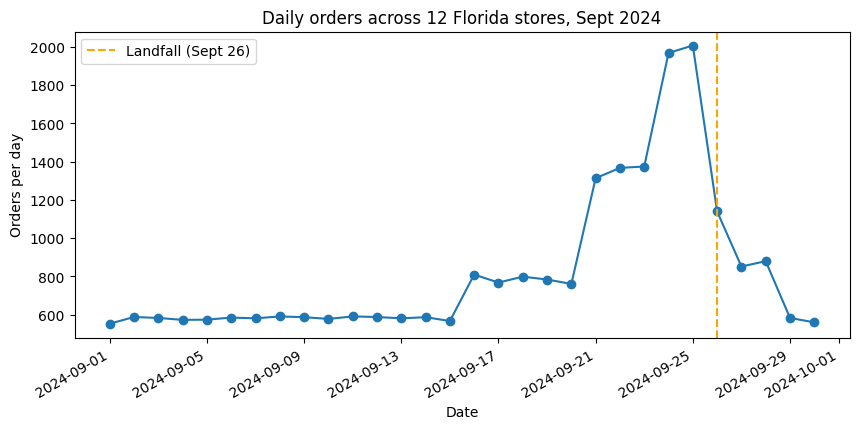

In [7]:
import matplotlib.pyplot as plt

daily_orders = clean_dated.groupby('date').size()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily_orders.index, daily_orders.values, marker='o')
ax.axvline(pd.Timestamp('2024-09-26'), color='orange', linestyle='--', label='Landfall (Sept 26)')
ax.set_xlabel('Date')
ax.set_ylabel('Orders per day')
ax.set_title('Daily orders across 12 Florida stores, Sept 2024')
ax.legend()
fig.autofmt_xdate()
plt.show()

# This chart makes sense. Sales would spike right before the hurricane makes landfall as people stock up.
# After the hurricane makes landfall, it is reasonable to expect the sales would drop aggressively

### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [8]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),   # from the team setup section
    'charter_committed': True,         # TODO: True once CHARTER.md shows in the git log above
}

progress = {
    'rows_after_cleaning': len(clean),        # an integer
    'decisions_logged': len(decision_log),           # how many entries in your log
    'canonical_products': None,         # distinct products after consolidation
    'weather_api_rows': len(weather_live),           # rows returned by your API call
    'notebook_runs_clean': True,       # True after Restart and Run All
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 25532
  done - decisions_logged = 24
  not yet - canonical_products = None
  done - weather_api_rows = 30
  done - notebook_runs_clean = True

required items complete: True
progress items done: 4 of 5


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** Weather is currently only pulled for Orlando, but the project needs data from stores all across Florida. Pulling in individual store data and making sure it joins correctly will be difficult. Right now, every store would be compared to Orlando's weather, which doesn't provide us accurate data.

**Plan, with an owner and a date:** Thomas will fix the per store weather loop using the new clean stores data, which now has the correct coordinates and formatting for all 12 stores. Ben will make sure that it correctly returns all 30 days for each store at our meeting.

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | In Progress (daily orders built and charted) | Ben |
| Q2 SKU consolidation | In Progress (3 of 20 product categories mapped) | Ben |
| Q3 weather correlation | In Progress (API working, joined to cleaned daily orders) | Thomas |
| Q4 store and geography | Not Started | Ben |
| Q5 signal or artifact | Not Started | Thomas |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.